# DRIFTS, MS and LabVIEW on one clock

Three instruments recorded the same operando run: OMNIC (DRIFTS spectra), a
Quadstar mass spectrometer and the LabVIEW process log. The data in
`data/drifts_run/` is an anonymised excerpt of a real run (40 spectra and about
six hours of MS and process data).

The point of this notebook: one `tos_start` for all three, so a value of `tos`
means the same moment everywhere, and one wall-clock window cut on all of them.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import lab_data_parser as ldp

In [2]:
RUN = Path("data") / "drifts_run"
tos_start = pd.Timestamp("2026-03-26 15:27:00", tz="Europe/Amsterdam")   # start of the reaction step

ir_raw = ldp.IRData.from_omnic_spa(RUN / "omnic", tos_start=tos_start, backend="omnic")
ms_raw = ldp.MSData.from_quadstar_asc(RUN / "ms" / "drifts-ms_run.asc", tos_start=tos_start)
lv_raw = ldp.ProcessData.from_labview_b67box5(RUN / "labview", tos_start=tos_start)

for name, data in (("ir", ir_raw), ("ms", ms_raw), ("lv", lv_raw)):
    print(f"{name}: {data.timestamps[0]} to {data.timestamps[-1]}")

ir: 2026-03-26 15:26:59+01:00 to 2026-03-26 21:18:08+01:00
ms: 2026-03-26 15:15:00.390000+01:00 to 2026-03-26 21:34:52.430000+01:00
lv: 2026-03-26 15:15:03+01:00 to 2026-03-26 21:34:57+01:00


## One window on all three

`select_timestamp_range` takes wall-clock bounds; a naive string is read in the
timezone of `tos_start`, so the times can be copied from the lab journal.

In [3]:
start, end = "2026-03-26 15:30", "2026-03-26 21:00"
ir_window, ms_window, lv_window = (d.select_timestamp_range(start, end) for d in (ir_raw, ms_raw, lv_raw))
print(ir_window.shape[0], "spectra,", ms_window.n_cycle, "ms cycles,", lv_window.n_samples, "process-data rows")

36 spectra, 1907 ms cycles, 3960 process-data rows


## Moving the origin

`with_tos_start` re-anchors `tos` but keeps the absolute timestamps; `tos = 0` is
then the new origin in all three datasets.

In [4]:
later = tos_start + pd.Timedelta(minutes=30)
shifted = ir_window.with_tos_start(later)
print("tos before:", ir_window.tos[:3])
print("tos after: ", shifted.tos[:3])
assert (shifted.timestamps == ir_window.timestamps).all()

tos before: [ 531. 1056. 1595.]
tos after:  [-1269.  -744.  -205.]


## A processing chain as a Pipeline

A `Pipeline` is a list of method names and keyword arguments. It runs on any data
object, is plain JSON, and is recorded step by step in the history of the
result.

In [5]:
drifts = ldp.Pipeline([
    ("select_wavenumber_range", {"min_cm": 1000, "max_cm": 3900}),
    ("correct_baseline", {"anchor_range_cm": (2600, 2500), "control_points_cm": [3900, 3450, 2720, 2500, 1850, 1000]}),
    ("smooth_savgol", {"window_length": 11, "polyorder": 3}),
], name="drifts example")

ir = drifts(ir_window)
ms = ms_window.correct_traces().mask_overloaded()
lv = lv_window.resample(60)
print(drifts.to_json())

{
  "name": "drifts example",
  "steps": [
    {
      "method": "select_wavenumber_range",
      "parameters": {
        "min_cm": 1000,
        "max_cm": 3900
      }
    },
    {
      "method": "correct_baseline",
      "parameters": {
        "anchor_range_cm": [
          2600,
          2500
        ],
        "control_points_cm": [
          3900,
          3450,
          2720,
          2500,
          1850,
          1000
        ]
      }
    },
    {
      "method": "smooth_savgol",
      "parameters": {
        "window_length": 11,
        "polyorder": 3
      }
    }
  ]
}


The history of the result can be turned back into a pipeline, ready to run
on the next experiment.

In [6]:
print(ir.format_history())
replay = ldp.Pipeline.from_history(ir)
replay

1. 2026-10-23T06:50:02+00:00  from_omnic_spa(filepath='data\\drifts_run\\omnic', wavenumber_to_si_factor=100.0, delta_time_seconds=null, tos_start='2026-03-26T15:27:00+01:00', strict_tos_start=true, bac...)
2. 2026-10-23T06:50:02+00:00  select_timestamp_range(start='2026-03-26 15:30', end='2026-03-26 21:00', empty='warn')
3. 2026-10-23T06:50:02+00:00  select_wavenumber_range(min_cm=1000, max_cm=3900)
4. 2026-10-23T06:50:02+00:00  correct_baseline(anchor_range_cm=[2600, 2500], control_points_cm=[3900, 3450, 2720, 2500, 1850, 1000], point_avg_half_width=0, double_offset=true)
5. 2026-10-23T06:50:02+00:00  smooth_savgol(window_length=11, polyorder=3)


Pipeline:
1. select_timestamp_range(start='2026-03-26 15:30', end='2026-03-26 21:00', empty='warn')
2. select_wavenumber_range(min_cm=1000, max_cm=3900)
3. correct_baseline(anchor_range_cm=[2600, 2500], control_points_cm=[3900, 3450, 2720, 2500, 1850, 1000], point_avg_half_width=0, double_offset=True)
4. smooth_savgol(window_length=11, polyorder=3)

## Plot on the shared time axis

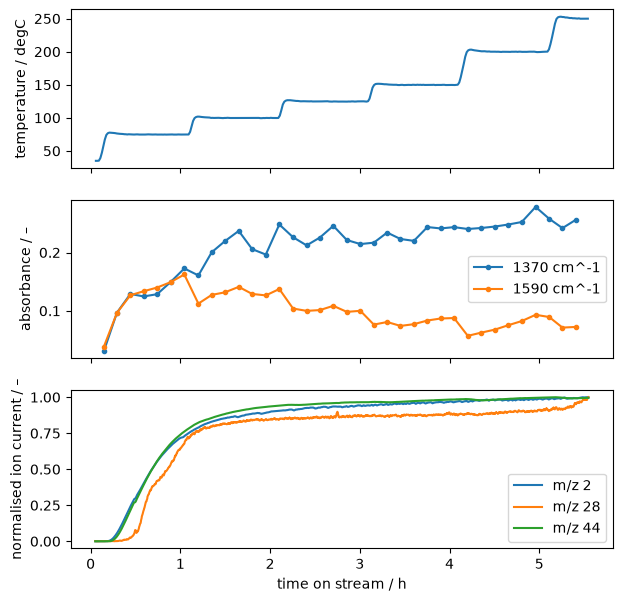

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(7, 7), sharex=True)

ax = axes[0]
ax.plot(lv.tos / 3600, lv.get_channel("Reactor T"))
ax.set_ylabel(f"temperature / {lv.get_channel_unit('Reactor T')}")

ax = axes[1]
for band in (1370, 1590):
    evolution = ir.get_evolution(band)
    ax.plot(evolution["tos"] / 3600, evolution, "o-", ms=3, label=f"{band} cm^-1")
ax.set_ylabel(f"{ir.data_type} / –")
ax.legend()

ax = axes[2]
for mz in (2, 28, 44):
    trace = ms.get_trace(mz, rolling_window=5, normalize=True)
    ax.plot(trace["tos"] / 3600, trace, label=f"m/z {mz}")
ax.set_ylabel("normalised ion current / –")
ax.set_xlabel("time on stream / h")
ax.legend()
plt.show()

## Spectra at chosen times

`average_scans_by_tos` averages the scans in a window around each target time.
The plot shows the region of the surface species, below the gas-phase CO2 bands.

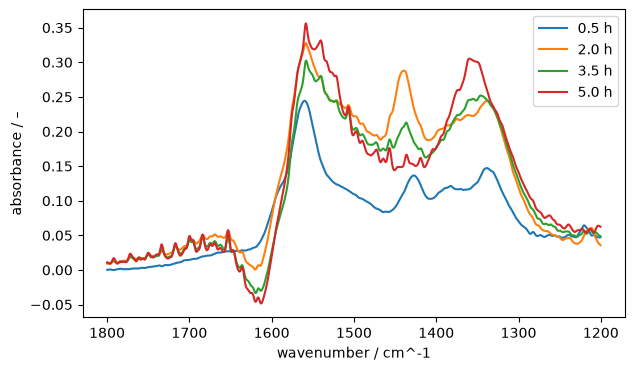

In [8]:
targets_s = [h * 3600 for h in (0.5, 2, 3.5, 5)]
averaged = (
    ir.average_scans_by_tos(targets_s, tolerance_seconds=None, time_window=20 * 60, direction="center")
    .select_wavenumber_range(1200, 1800)
)
fig, ax = plt.subplots(figsize=(7, 4))
for i, target in enumerate(targets_s):
    ax.plot(averaged.wavenumber_per_cm, averaged.values[i], label=f"{target / 3600:.1f} h")
ax.invert_xaxis()
ax.set_xlabel(ir.axis_label("cm^-1"))
ax.set_ylabel(f"{ir.data_type} / –")
ax.legend()
plt.show()